# 03 — Le nettoyage : la couche silver

Ici, on passe des mesures brutes (bronze) à des **heures propres et alignées** (silver) : une ligne par capteur, par
segment de position et par heure UTC, avec la valeur de la station EEA, l'humidité officielle et, quand on peut lui faire
confiance, l'humidité de la sonde du capteur. On voulait que chaque règle de nettoyage soit justifiée par les données, et
que chaque retrait soit compté.

Le notebook suit cet ordre :

1. les mesures de particules : les règles, deux exemples, et le cas des valeurs figées en air propre ;
2. le passage à l'heure, qui dépend de la cadence de chaque capteur ;
3. les capteurs qui ont déménagé : un appariement par segment ;
4. la référence EEA ;
5. l'humidité, officielle en priorité, sonde en complément ;
6. le contrôle d'horloge automatique sur toutes les paires ;
7. l'entonnoir complet et le découpage par station.

Trois principes ont guidé tout le nettoyage :

1. **On ne supprime aucune ligne.** Chaque mesure (ou heure) reçoit un statut `quality_flag` : `ok`, ou la **première**
   règle qu'elle ne respecte pas. Le rapport d'entonnoir (`reports/funnel.md`) est calculé directement à partir de ces
   statuts.
2. **Seulement des règles physiques ou de cohérence.** Pas de filtre statistique d'aberrations (z-score, écart
   interquartile…) sur les particules : un pic par forte humidité, c'est précisément ce que le modèle doit apprendre à
   corriger.
3. **L'humidité officielle** (DWD, Météo-France) passe en premier ; la sonde du capteur reste secondaire, puisque le
   notebook 02 a montré que seules 38,9 % des heures-sondes sont utilisables.

Quelques définitions :

- **Couche silver** : les données nettoyées, une ligne par heure, chacune avec son statut.
- **Segment de position** : une période pendant laquelle un capteur ne bouge pas. Un capteur qui a déménagé a plusieurs
  segments, chacun associé à sa propre station.
- **Paire** : un segment de capteur et sa station de référence. **Heure-paire** : une heure de cette paire où le capteur
  et la station ont chacun une valeur.
- **Cadence** : l'intervalle habituel entre deux mesures d'un capteur.
- **Complétude** d'une heure : le nombre de mesures valides divisé par le nombre qu'on attendait à la cadence du capteur.

Les commandes sont `python -m aircalib silver` puis `python -m aircalib pair`. Les règles sont dans
`src/aircalib/transform/` (fonctions pures, testées) et les étapes dans `src/aircalib/silver/`.

## 0. Préparation

On charge la configuration, les modules de règles et les tables silver. Le nettoyage lui-même a été fait par les commandes
ci-dessus ; ici, on se contente de montrer et de vérifier.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.silver import report
from aircalib.transform import clock
from aircalib.transform import particles as pt

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
B, S = settings.paths.bronze, settings.paths.silver
SC, PAIRS = S / "sensor_community", S / "pairs"
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pl.Config.set_engine_affinity("streaming")
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(14)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
root = settings.paths.data_dir.parent
print("période :", settings.period.start, "→", settings.period.end, "| silver :", S.relative_to(root))

période : 2024-01-01 → 2025-12-31 | silver : data/silver


## 1. Les mesures de particules (SDS011)

Première question : quelles mesures sont physiquement impossibles ou incohérentes, et combien y en a-t-il ? Chaque
mesure reçoit son statut, dans cet ordre (`transform/particles.py`) :

| règle | condition | pourquoi |
|---|---|---|
| `pm_missing` | PM10 ou PM2.5 vide ou `NaN` | pas de mesure |
| `duplicate` | même horodatage et mêmes valeurs qu'une mesure précédente | une copie : on garde la première |
| `duplicate_conflict` | même horodatage, valeurs différentes | impossible de savoir laquelle est la bonne : on les écarte toutes |
| `pm_negative` | PM < 0 | une concentration est positive (le capteur écrit −1/−1 quand il est en erreur) |
| `pm_saturated` | PM2.5 ≥ 999,9 ou PM10 ≥ 1 999,9 | le plafond du capteur, qu'on voit dans l'archive |
| `pm_above_range` | PM > 999,9 µg/m³ | en dehors de ce que le SDS011 sait mesurer |
| `pm25_above_pm10` | PM2.5 > PM10 | incohérent : le PM2.5 fait partie du PM10 |
| `pm_stuck` | valeurs identiques ≥ 1 h **et** (code de panne 0/0 **ou** station qui varie ≥ 5 µg/m³) | capteur figé (sections 1.2 et 1.3) |

Comme une mesure n'est comptée que dans la première règle qu'elle enfreint, l'entonnoir s'additionne sans double compte.

In [2]:
particle_funnel = report._explain(report.particle_funnel(settings), report.PARTICLE_REASONS)
particle_funnel.with_columns(pct_retiré=(100 * pl.col("removed") / pl.col("remaining").first()).round(3))

step,raison,removed,remaining,capteurs_lost,capteurs_remaining,segments_lost,segments_remaining,pct_retiré
str,str,i64,i64,i64,i64,i64,i64,f64
"""start""","""point de départ""",0,377950455,0,1399,0,1479,0.0
"""pm_missing""","""PM10 ou PM2.5 vide / NaN""",794913,377155542,1,1398,2,1477,0.21
"""duplicate""","""doublon exact (même horodatage, mêmes valeurs) : la 1re copie est gardée""",156,377155386,0,1398,0,1477,0.0
"""duplicate_conflict""","""même horodatage, valeurs différentes : impossible de choisir""",3286,377152100,0,1398,0,1477,0.001
"""pm_negative""","""valeur négative (code d'erreur −1 du firmware)""",447649,376704451,0,1398,0,1477,0.118
"""pm_saturated""","""saturation du capteur (PM2.5 = 999,9 avec PM10 = 1 999,9)""",2619590,374084861,2,1396,2,1475,0.693
"""pm_above_range""","""au-delà de la plage du SDS011 (999,9 µg/m³)""",196594,373888267,0,1396,0,1475,0.052
"""pm25_above_pm10""","""PM2.5 > PM10 : incohérent (PM2.5 fait partie de PM10)""",786986,373101281,0,1396,0,1475,0.208
"""pm_stuck""","""valeurs identiques ≥ 1 h ET (code de panne 0/0 OU station qui varie ≥ 5 µg/m³) :…",2555802,370545479,0,1396,0,1475,0.676


On regarde aussi combien de capteurs sont concernés par chaque défaut, et si deux capteurs suffisent à l'expliquer :

In [3]:
readings = pl.scan_parquet(SC / "pm" / "*.parquet").with_columns(pl.col("quality_flag").cast(pl.String))
by_sensor = (
    readings.filter(pl.col("quality_flag") != pt.OK)
    .group_by("quality_flag")
    .agg(mesures=pl.len(), capteurs=pl.col("sensor_id").n_unique())
    .collect()
)
concentration = (
    readings.filter(pl.col("quality_flag") != pt.OK)
    .group_by("quality_flag", "sensor_id")
    .agg(n=pl.len())
    .sort("n", descending=True)
    .group_by("quality_flag", maintain_order=True)
    .agg(part_des_2_premiers_capteurs=(pl.col("n").head(2).sum() / pl.col("n").sum()).round(3))
    .collect()
)
by_sensor.join(concentration, on="quality_flag").sort("mesures", descending=True)

quality_flag,mesures,capteurs,part_des_2_premiers_capteurs
str,u32,u32,f64
"""pm_saturated""",2619590,360,0.237
"""pm_stuck""",2555802,178,0.257
"""pm_missing""",794913,248,0.926
"""pm25_above_pm10""",786986,18,0.999
"""pm_negative""",447649,10,0.886
"""pm_above_range""",196594,565,0.402
"""duplicate_conflict""",3286,23,0.861
"""duplicate""",156,5,0.981


Sur 377,95 millions de mesures, **7,41 millions (2,0 %) sont écartées**. Les deux grosses causes sont des pannes
franches : les capteurs **saturés** (2,62 millions de mesures, 360 capteurs) et les capteurs **figés** (2,56 millions,
178 capteurs). D'autres règles ne concernent qu'une poignée de capteurs : 99,9 % des PM2.5 > PM10 viennent de 2 capteurs,
et le code −1/−1 de 10 capteurs. Le dépassement de plage (> 999,9 µg/m³), lui, est réparti sur 565 capteurs.

On garde donc 98 % des mesures, et ce qu'on retire, ce sont des pannes, pas des mesures qui dérangent.

> **Vérification.** Aucun filtre statistique : un pic à 850 µg/m³ dans un air propre reste `ok`. Le test unitaire
> `test_no_statistical_outlier_filter` vérifie que ça reste vrai.

### 1.1 Deux exemples : un capteur saturé, un capteur incohérent

Pour s'assurer que ces règles touchent bien des pannes et pas des pics plausibles, on a tracé deux vrais capteurs avec
leurs statuts : le 23046 (bloqué au plafond de 999,9) et le 76986 (PM2.5 > PM10 en permanence).

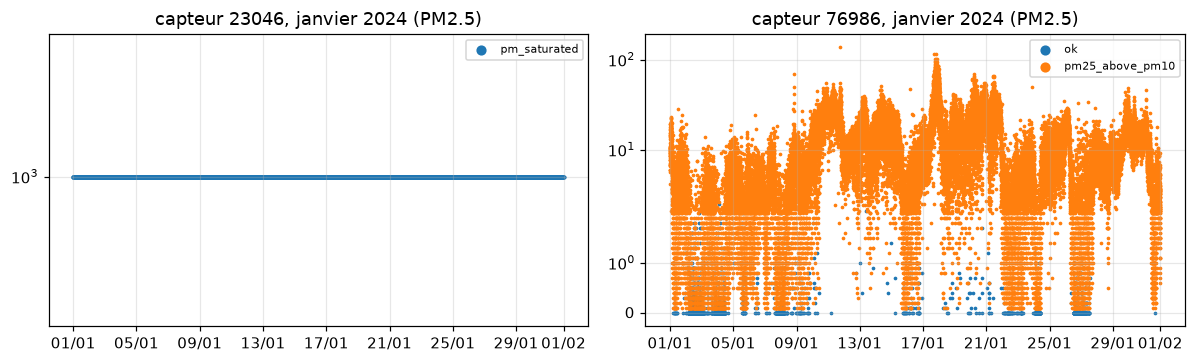

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, sensor_id in zip(axes, (23046, 76986), strict=True):
    path = SC / "pm" / f"{sensor_id}.parquet"
    if not path.exists():
        ax.set_title(f"capteur {sensor_id} absent de ce mode")
        continue
    one = (
        pl.read_parquet(path)
        .with_columns(pl.col("quality_flag").cast(pl.String))
        .filter(pl.col("timestamp").dt.month() == 1, pl.col("timestamp").dt.year() == 2024)
    )
    for flag, part in one.group_by("quality_flag"):
        ax.scatter(part["timestamp"], part["P2"], s=2, label=flag[0])
    ax.set_yscale("symlog")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_title(f"capteur {sensor_id}, janvier 2024 (PM2.5)")
    ax.legend(fontsize=7, markerscale=4)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_exemples_statuts.png")

Le premier reste coincé au plafond (999,9 µg/m³) pendant tout le mois. Le second a presque toutes ses mesures
incohérentes (PM2.5 > PM10), et les rares mesures cohérentes sont proches de zéro. Ni l'un ni l'autre ne mesure l'air réel
pendant ce mois.

### 1.2 À partir de quand un capteur est-il « figé » ?

Dans l'air réel, un compteur optique fluctue d'une mesure à l'autre. Mais au bout de combien de temps une valeur répétée
devient-elle suspecte ? Pour le savoir, on a reconstitué toutes les **séries de valeurs identiques** de chaque capteur,
classées par valeur et par durée, et regardé ce que mesurait la station pendant ce temps.

In [5]:
eea = pl.read_parquet(S / "eea" / "hourly.parquet").filter(
    pl.col("pollutant") == "pm25", pl.col("quality_flag") == "ok"
)
pairs_plan = pl.read_parquet(B / "reference" / "pairs.parquet").select("sensor_id", "sampling_point")
runs = []
for sensor_id in pairs_plan["sensor_id"].to_list():
    path = SC / "pm" / f"{sensor_id}.parquet"
    if not path.exists():
        continue
    one = pl.read_parquet(path, columns=["sensor_id", "timestamp", "P1", "P2", "quality_flag"]).with_columns(
        pl.col("quality_flag").cast(pl.String)
    )
    one = one.filter(pl.col("quality_flag").is_in([pt.OK, pt.PM_STUCK, pt.PM_SATURATED, pt.PM_NEGATIVE]))
    t = pl.col("timestamp")
    same = (pl.col("P1") == pl.col("P1").shift()) & (pl.col("P2") == pl.col("P2").shift())
    one = one.with_columns(run=(~same.fill_null(False)).cum_sum())
    runs.append(
        one.group_by("sensor_id", "run")
        .agg(n=pl.len(), t0=t.min(), t1=t.max(), p1=pl.col("P1").first(), p2=pl.col("P2").first())
        .filter(pl.col("n") >= 5)
    )
runs = pl.concat(runs).with_columns(hours=(pl.col("t1") - pl.col("t0")).dt.total_seconds() / 3600)
runs = runs.filter(pl.col("hours") >= 0.5).join(pairs_plan, on="sensor_id")
during = (
    runs.with_columns(
        hour=pl.datetime_ranges(pl.col("t0").dt.truncate("1h"), pl.col("t1").dt.truncate("1h"), "1h")
    )
    .explode("hour")
    .join(eea.select("sampling_point", "hour", "value"), on=["sampling_point", "hour"])
    .group_by("sensor_id", "run")
    .agg(station_médiane=pl.col("value").median())
)
runs = runs.join(during, on=["sensor_id", "run"], how="left").with_columns(
    valeur=pl.when(pl.col("p2") >= 999.9)
    .then(pl.lit("999,9 (saturé)"))
    .when(pl.col("p2") < 0)
    .then(pl.lit("−1 (erreur)"))
    .when((pl.col("p1") == 0) & (pl.col("p2") == 0))
    .then(pl.lit("0 / 0"))
    .when(pl.col("p2") < 1)
    .then(pl.lit("< 1 µg/m³"))
    .otherwise(pl.lit("≥ 1 µg/m³")),
    durée=pl.when(pl.col("hours") < 1)
    .then(pl.lit("a. 30 min – 1 h"))
    .when(pl.col("hours") < 3)
    .then(pl.lit("b. 1 – 3 h"))
    .when(pl.col("hours") < 24)
    .then(pl.lit("c. 3 – 24 h"))
    .otherwise(pl.lit("d. ≥ 24 h")),
)
runs.group_by("valeur", "durée").agg(
    séries=pl.len(),
    mesures=pl.col("n").sum(),
    capteurs=pl.col("sensor_id").n_unique(),
    station_médiane=pl.col("station_médiane").median().round(1),
).sort("valeur", "durée")

valeur,durée,séries,mesures,capteurs,station_médiane
str,str,u32,u32,u32,f64
"""0 / 0""","""a. 30 min – 1 h""",25915,434005,183,5.3
"""0 / 0""","""b. 1 – 3 h""",12595,455527,152,5.1
"""0 / 0""","""c. 3 – 24 h""",3955,622324,101,6.0
"""0 / 0""","""d. ≥ 24 h""",384,1226130,42,6.6
"""999,9 (saturé)""","""a. 30 min – 1 h""",393,7296,65,6.1
"""999,9 (saturé)""","""b. 1 – 3 h""",457,18651,63,6.3
"""999,9 (saturé)""","""c. 3 – 24 h""",504,106804,55,6.9
"""999,9 (saturé)""","""d. ≥ 24 h""",140,2306416,36,6.9
"""< 1 µg/m³""","""a. 30 min – 1 h""",32374,523276,210,6.0


Les longues séries identiques sont **toutes** des valeurs de panne : 0/0, moins de 1 µg/m³, le code −1 ou le plafond de
999,9. Pendant ce temps, la station mesure une pollution tout à fait ordinaire (5 à 7 µg/m³ en médiane). À l'inverse, une
valeur d'au moins 1 µg/m³ ne se répète presque jamais pendant une heure : 14 séries de 1 à 3 h, sur 6 capteurs, en deux
ans.

Une heure semble donc une bonne durée pour repérer une panne. Mais la durée seule ne suffit pas : en air très propre, un
capteur peut répéter une petite valeur sans être en panne. C'est ce qu'on vérifie juste après.

### 1.3 La règle « figé » vise-t-elle l'air propre ?

Un SDS011 mesure au dixième de µg/m³ près. Par temps calme et propre, il peut donc très bien afficher 0,3 µg/m³ pendant
une heure. Si notre règle de panne retirait en priorité ces heures-là, on pousserait le modèle vers les fortes
concentrations sans s'en rendre compte.

On compare donc les heures couvertes par un plateau d'au moins une heure aux heures gardées : quelle part a une valeur EEA
sous 5 µg/m³ ? Puis on teste une règle plus fine :

- un plateau qui correspond à un **code de panne connu** (0/0) est figé ;
- sinon, il n'est figé **que si la station a varié d'au moins 5 µg/m³** pendant ce temps
  (`particles.stuck_reference_range_ugm3`, la même marge que le bruit des analyseurs EEA autour de zéro) ;
- sinon (air calme, station stable), on garde la mesure.

In [6]:
limit = settings.particles.stuck_min_hours
plateaus = runs.filter(
    pl.col("hours") >= limit, pl.col("p2") >= 0, pl.col("p2") < settings.particles.pm25_saturation_ugm3
)
plateau_hours = (
    plateaus.with_columns(
        hour=pl.datetime_ranges(pl.col("t0").dt.truncate("1h"), pl.col("t1").dt.truncate("1h"), "1h")
    )
    .explode("hour")
    .join(eea.select("sampling_point", "hour", "value"), on=["sampling_point", "hour"])
)
moves = plateau_hours.group_by("sensor_id", "run").agg(
    station_range=pl.col("value").max() - pl.col("value").min()
)
code = pl.any_horizontal(
    [(pl.col("p1") == a) & (pl.col("p2") == b) for a, b in settings.particles.stuck_codes]
)
verdict = (
    plateaus.join(moves, on=["sensor_id", "run"], how="left")
    .with_columns(
        verdict=pl.when(code)
        .then(pl.lit("figé : code 0/0"))
        .when(pl.col("station_range") >= settings.particles.stuck_reference_range_ugm3)
        .then(pl.lit("figé : la station a varié"))
        .otherwise(pl.lit("gardé : air calme"))
    )
    .select("sensor_id", "run", "verdict", "n")
)
plateau_hours = plateau_hours.join(verdict, on=["sensor_id", "run"])
kept = pl.read_parquet(PAIRS / "pair_hours.parquet", columns=["status", "ref_pm25"]).filter(
    pl.col("status") == "ok"
)


def describe(frame: pl.DataFrame, label: str) -> pl.DataFrame:
    v = pl.col("value") if "value" in frame.columns else pl.col("ref_pm25")
    return frame.select(
        groupe=pl.lit(label),
        heures=pl.len(),
        médiane=v.median().round(1),
        q25=v.quantile(0.25).round(1),
        part_sous_3=(v < 3).mean().round(3),
        part_sous_5=(v < 5).mean().round(3),
    )


print(verdict.group_by("verdict").agg(plateaux=pl.len(), mesures=pl.col("n").sum()).sort("verdict"))
pl.concat(
    [
        describe(kept, "heures gardées (référence)"),
        describe(plateau_hours, "toutes les heures de plateaux ≥ 1 h"),
        *[describe(part, label[0]) for label, part in plateau_hours.group_by("verdict", maintain_order=True)],
    ]
)

shape: (3, 3)
┌───────────────────────────┬──────────┬─────────┐
│ verdict                   ┆ plateaux ┆ mesures │
│ ---                       ┆ ---      ┆ ---     │
│ str                       ┆ u32      ┆ u32     │
╞═══════════════════════════╪══════════╪═════════╡
│ figé : code 0/0           ┆ 16934    ┆ 2303981 │
│ figé : la station a varié ┆ 746      ┆ 265082  │
│ gardé : air calme         ┆ 12163    ┆ 514083  │
└───────────────────────────┴──────────┴─────────┘


groupe,heures,médiane,q25,part_sous_3,part_sous_5
str,u32,f64,f64,f64,f64
"""heures gardées (référence)""",13822352,7.2,4.5,0.111,0.297
"""toutes les heures de plateaux ≥ 1 h""",174144,6.2,3.9,0.147,0.369
"""figé : code 0/0""",131070,6.3,4.0,0.146,0.36
"""gardé : air calme""",32969,5.6,3.6,0.158,0.42
"""figé : la station a varié""",10105,7.4,4.0,0.129,0.31


Notre première intuition se confirme : la durée seule visait trop l'air propre. 36,9 % des heures de plateau ont une
valeur EEA sous 5 µg/m³, contre 29,7 % pour les heures gardées. Avec la règle plus fine :

- les **plateaux 0/0** (16 934 plateaux, 2,30 millions de mesures) restent figés. Ils penchent encore un peu vers l'air
  propre (36 % sous 5 µg/m³), mais la station mesure 6,3 µg/m³ en médiane pendant que le capteur affiche zéro ;
- les **plateaux pendant lesquels la station a varié d'au moins 5 µg/m³** (746 plateaux, 0,27 million de mesures) sont
  figés, et ils ressemblent aux heures gardées (31 % sous 5 µg/m³) ;
- les **plateaux en air calme** (12 163 plateaux, 0,51 million de mesures) sont **gardés**. Ce sont bien les heures les
  plus propres (42 % sous 5 µg/m³).

On a donc remplacé la règle simple (« identique pendant au moins 1 h = figé »), biaisée vers l'air propre, par la règle
conditionnelle. On accepte que les plateaux à zéro restent figés même s'ils penchent un peu vers l'air propre : dans ces
cas-là, le capteur ne voit plus la pollution que la station mesure.

## 2. Le passage à l'heure : une complétude qui dépend de chaque capteur

Combien de mesures faut-il dans une heure pour que sa moyenne ait du sens ? Le problème, c'est que les capteurs
n'envoient pas tous au même rythme.

Pour chaque capteur et chaque mois, on prend comme **cadence** la médiane des écarts entre deux mesures consécutives.
Pour chaque heure, on calcule à partir des seules mesures `ok` la moyenne, la médiane, l'écart-type et le nombre de
mesures (qui serviront de variables), puis la complétude :

$$
\text{complétude} = \frac{n_{\text{valides}}}{3600 / \text{cadence}}
$$

avec $n_{\text{valides}}$ le nombre de mesures `ok` de l'heure, et $3600 / \text{cadence}$ le nombre de mesures attendues
(les 3 600 secondes d'une heure divisées par l'écart entre deux mesures). On garde une heure si sa complétude atteint
**75 %** (`particles.min_completeness`).

cadence médiane par capteur (s) : 125.0 / 146.0 / 301.0 (5 % / médiane / 95 %)
shape: (6, 2)
┌────────┬──────┐
│ classe ┆ len  │
│ ---    ┆ ---  │
│ f64    ┆ u32  │
╞════════╪══════╡
│ 150.0  ┆ 1146 │
│ 180.0  ┆ 69   │
│ 300.0  ┆ 55   │
│ 60.0   ┆ 35   │
│ 120.0  ┆ 21   │
│ 240.0  ┆ 15   │
└────────┴──────┘


hour_flag,heures,part
str,u32,f64
"""incomplete_hour""",800252,0.0511
"""no_valid_reading""",230389,0.0147
"""ok""",14637759,0.9342


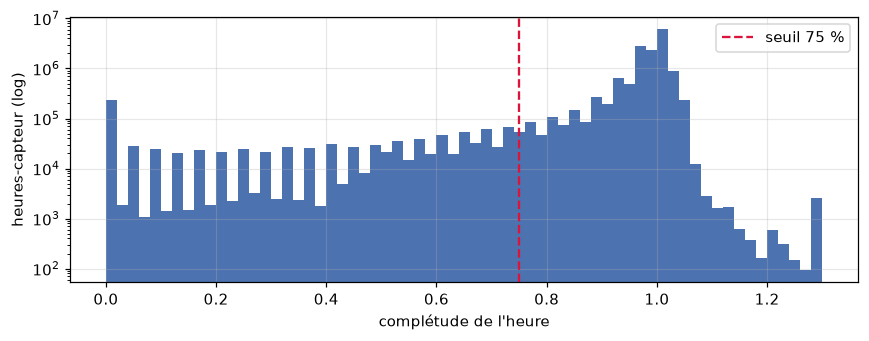

In [7]:
pm_hourly = pl.read_parquet(SC / "pm_hourly.parquet")
cadence = pm_hourly.group_by("sensor_id").agg(cadence_s=pl.col("cadence_s").median())
print(
    "cadence médiane par capteur (s) :",
    cadence["cadence_s"].quantile(0.05),
    "/",
    cadence["cadence_s"].median(),
    "/",
    cadence["cadence_s"].quantile(0.95),
    "(5 % / médiane / 95 %)",
)
print(
    cadence.group_by(classe=(pl.col("cadence_s") / 30).round() * 30)
    .len()
    .sort("len", descending=True)
    .head(6)
)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(pm_hourly["completeness"].drop_nulls().clip(0, 1.3), bins=65, color="#4C72B0")
ax.axvline(settings.particles.min_completeness, color="crimson", ls="--", label="seuil 75 %")
ax.set_yscale("log")
ax.set_xlabel("complétude de l'heure")
ax.set_ylabel("heures-capteur (log)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_completude_horaire.png")
pm_hourly.group_by("hour_flag").agg(heures=pl.len()).with_columns(
    part=(pl.col("heures") / pl.col("heures").sum()).round(4)
)

Pour les heures qui n'ont aucune mesure valide, on regarde quel défaut domine :

In [8]:
lost = (
    pm_hourly.filter(pl.col("hour_flag") == pt.NO_VALID_READING)
    .group_by("main_flag")
    .agg(heures=pl.len())
    .sort("heures", descending=True)
)
lost.with_columns(part=(pl.col("heures") / pl.col("heures").sum()).round(3))

main_flag,heures,part
str,u32,f64
"""pm_saturated""",108743,0.472
"""pm_stuck""",78222,0.34
"""pm_negative""",28198,0.122
"""pm25_above_pm10""",9916,0.043
"""pm_above_range""",5201,0.023
"""pm_missing""",109,0.0


La cadence médiane est de **146 s**, mais 5 % des capteurs envoient une mesure toutes les 125 s ou moins, et 5 % toutes
les 300 s ou plus. Sur 15,67 millions d'heures-capteur, **93,4 % sont complètes**, 5,1 % incomplètes (< 75 %) et 1,5 %
n'ont aucune mesure valide, surtout à cause de la saturation (47 %) et des capteurs figés (34 %).

Avec un seuil fixe, du genre « au moins 18 mesures par heure », on aurait éliminé à tort les quelque 250 capteurs lents,
et laissé passer des heures à moitié vides chez les capteurs rapides. On a donc gardé une complétude relative à la cadence
de chaque capteur, avec un seuil de 75 %, le même que pour une moyenne journalière réglementaire (18 heures sur 24).

## 3. Les capteurs qui ont déménagé : un appariement par segment

Le notebook 02 a repéré 65 capteurs qui ont bougé. Mais avec quelle station comparer chaque période de leur vie ? On
découpe chaque capteur en **segments** (des suites de mesures au même site et aux mêmes coordonnées ; revenir à une
ancienne adresse ouvre un nouveau segment), puis on associe **chaque segment** à une station avec la même règle qu'au
notebook 01 : la plus proche à 3 km ou moins, avec des heures vérifiées pendant le segment.

In [9]:
segments = pl.read_parquet(PAIRS / "segment_pairs.parquet")
planned = pl.read_parquet(B / "reference" / "pairs.parquet").select(
    "sensor_id", planned_point="sampling_point"
)
segments = segments.join(planned, on="sensor_id", how="left").with_columns(
    situation=pl.when(pl.col("pair_status") != "ok")
    .then(pl.col("pair_status"))
    .when(pl.col("sampling_point") == pl.col("planned_point"))
    .then(pl.lit("même station que prévu"))
    .otherwise(pl.lit("autre station"))
)
moved = segments.filter(pl.col("segment") > 1)["sensor_id"].n_unique()
n_sensors = segments["sensor_id"].n_unique()
print(f"{segments.height} segments pour {n_sensors} capteurs ; capteurs déplacés : {moved}")
print(
    segments.group_by("situation").agg(
        segments=pl.len(), capteurs=pl.col("sensor_id").n_unique(), mesures=pl.col("n_readings").sum()
    )
)
segments.filter(pl.col("situation") != "même station que prévu").select(
    "sensor_id",
    "segment",
    "start",
    "end",
    "lat",
    "lon",
    "sampling_point",
    "distance_km",
    "planned_point",
    "situation",
).sort("start").head(15)

1479 segments pour 1399 capteurs ; capteurs déplacés : 65
shape: (3, 4)
┌────────────────────────┬──────────┬──────────┬───────────┐
│ situation              ┆ segments ┆ capteurs ┆ mesures   │
│ ---                    ┆ ---      ┆ ---      ┆ ---       │
│ str                    ┆ u32      ┆ u32      ┆ u32       │
╞════════════════════════╪══════════╪══════════╪═══════════╡
│ même station que prévu ┆ 1445     ┆ 1399     ┆ 375621751 │
│ no_reference_station   ┆ 22       ┆ 19       ┆ 1012647   │
│ autre station          ┆ 12       ┆ 10       ┆ 1316057   │
└────────────────────────┴──────────┴──────────┴───────────┘


sensor_id,segment,start,end,lat,lon,sampling_point,distance_km,planned_point,situation
i64,u32,datetime[μs],datetime[μs],f64,f64,str,f64,str,str
68184,1,2024-01-01 00:00:21,2024-06-28 09:05:59,48.7705,9.1372481,null,null,"""SPO.DE_DEBW081_PM2_dataGroup1""","""no_reference_station"""
42694,1,2024-01-01 00:00:34,2024-04-08 23:58:08,50.851567,4.349553,null,null,"""SPO.DE_DENW082_PM2_dataGroup1""","""no_reference_station"""
34433,1,2024-01-01 00:00:37,2024-04-18 15:18:40,48.562,13.384,null,null,"""SPO.DE_DEBY118_PM2_dataGroup1""","""no_reference_station"""
27263,1,2024-01-01 00:00:40,2024-03-08 19:26:48,52.499043,13.440547,"""SPO.DE_DEBE034_PM2_dataGroup1""",1.252892,"""SPO.DE_DEBE068_PM2_dataGroup1""","""autre station"""
81487,1,2024-01-01 00:00:59,2025-08-10 17:58:06,52.464,13.428,"""SPO.DE_DEBE127_PM2_dataGroup1""",0.974536,"""SPO.DE_DEBE010_PM2_dataGroup1""","""autre station"""
75419,1,2024-01-01 00:01:15,2024-03-31 10:02:51,52.488,13.428,"""SPO.DE_DEBE034_PM2_dataGroup1""",0.250943,"""SPO.DE_DEBE065_PM2_dataGroup1""","""autre station"""
35807,1,2024-01-01 00:01:21,2025-02-19 07:21:24,52.413698,13.27334,null,null,"""SPO.DE_DEBE069_PM2_dataGroup1""","""no_reference_station"""
45248,1,2024-01-01 00:01:48,2025-12-09 08:46:30,48.489218,9.214437,"""SPO.DE_DEBW147_PM2_dataGroup1""",0.269035,"""SPO.DE_DEBW027_PM2_dataGroup1""","""autre station"""
9232,1,2024-01-01 00:02:18,2024-07-09 19:50:09,52.52,13.464,"""SPO.DE_DEBE065_PM2_dataGroup1""",0.771878,"""SPO.DE_DESN077_PM2_dataGroup1""","""autre station"""


On obtient 1 479 segments pour 1 399 capteurs. **1 445 segments** gardent la station prévue. **12 segments** (10 capteurs,
1,3 million de mesures) ont, à leur autre adresse, une **autre station** plus proche. Et **22 segments** (19 capteurs,
1,0 million de mesures) n'ont **aucune station à 3 km** : c'est le cas du capteur 84804 quand il était à Hanoï, ou du
42694, à Bruxelles jusqu'en avril 2024. Leurs heures sont gardées, avec le statut `no_reference_station`.

Sans ce découpage, 2,3 millions de mesures auraient été comparées à la mauvaise station, parfois à des milliers de
kilomètres.

## 4. La référence EEA

Quelles heures de la station peut-on garder, et que faire des petites valeurs négatives ? L'heure UTC est
`Start − 1 h` (établi au notebook 01, et revérifié à la section 6). Chaque heure peut recevoir trois statuts : `invalid`
(drapeau refusé ou valeur −999), `not_verified`, ou `negative_beyond_uncertainty`. Il faut savoir que les analyseurs
automatiques mesurent avec un bruit de quelques µg/m³ autour de zéro, si bien que l'agence valide parfois de petites
valeurs négatives.

In [10]:
eea_all = pl.read_parquet(S / "eea" / "hourly.parquet")
negatives = eea_all.filter(pl.col("value") < 0, pl.col("value") != settings.eea.missing_sentinel)
print(
    negatives.group_by("pollutant", "quality_flag").agg(
        heures=pl.len(),
        points=pl.col("sampling_point").n_unique(),
        médiane=pl.col("value").median(),
        minimum=pl.col("value").min(),
    )
)
report._explain(report.reference_funnel(settings), report.REFERENCE_REASONS)

shape: (4, 6)
┌───────────┬─────────────────────────────┬────────┬────────┬─────────┬─────────┐
│ pollutant ┆ quality_flag                ┆ heures ┆ points ┆ médiane ┆ minimum │
│ ---       ┆ ---                         ┆ ---    ┆ ---    ┆ ---     ┆ ---     │
│ str       ┆ str                         ┆ u32    ┆ u32    ┆ f64     ┆ f64     │
╞═══════════╪═════════════════════════════╪════════╪════════╪═════════╪═════════╡
│ pm10      ┆ ok                          ┆ 849    ┆ 32     ┆ -0.7    ┆ -4.441  │
│ pm25      ┆ ok                          ┆ 8955   ┆ 36     ┆ -0.79   ┆ -4.901  │
│ pm10      ┆ negative_beyond_uncertainty ┆ 1      ┆ 1      ┆ -5.16   ┆ -5.16   │
│ pm25      ┆ negative_beyond_uncertainty ┆ 1      ┆ 1      ┆ -6.241  ┆ -6.241  │
└───────────┴─────────────────────────────┴────────┴────────┴─────────┴─────────┘


step,raison,removed,remaining,points_lost,points_remaining,polluant
str,str,i64,i64,i64,i64,str
"""start""","""point de départ""",0,5034394,0,298,"""pm25"""
"""invalid""","""drapeau de validité refusé ou sentinelle −999""",160414,4873980,0,298,"""pm25"""
"""not_verified""","""heure non vérifiée par l'agence""",0,4873980,0,298,"""pm25"""
"""negative_beyond_uncertainty""","""valeur < −5 µg/m³ (`eea.negative_floor_ugm3`) : au-delà du bruit autour de 0""",1,4873979,0,298,"""pm25"""
"""usable""","""**utilisable**""",0,4873979,0,298,"""pm25"""
"""start""","""point de départ""",0,4764209,0,277,"""pm10"""
"""invalid""","""drapeau de validité refusé ou sentinelle −999""",88798,4675411,0,277,"""pm10"""
"""not_verified""","""heure non vérifiée par l'agence""",0,4675411,0,277,"""pm10"""
"""negative_beyond_uncertainty""","""valeur < −5 µg/m³ (`eea.negative_floor_ugm3`) : au-delà du bruit autour de 0""",1,4675410,0,277,"""pm10"""


Sur 5,03 millions d'heures PM2.5, 3,2 % sont invalides et **aucune n'est non vérifiée**. Les valeurs négatives validées
sont rares (8 955 heures PM2.5 sur 36 points, médiane −0,79, minimum −4,9). Une seule heure PM2.5 descend sous
−5 µg/m³ (−6,2).

Pour ces valeurs négatives, on avait trois options : les mettre à 0, les supprimer ou les garder. Les deux premières
**biaiseraient la cible vers le haut** en air propre. On garde donc les petites valeurs négatives telles quelles, et on
n'écarte que celles sous −5 µg/m³ (`eea.negative_floor_ugm3`), qui ne relèvent plus du bruit.

## 5. L'humidité : l'officielle d'abord, la sonde en complément

### 5.1 Quelle station météo pour chaque paire ?

Parmi les deux stations météo retenues pour chaque station EEA, on prend la plus proche **du capteur**. Si les deux sont
à moins de 0,5 km d'écart (`weather.tie_km`), on prend la plus complète. Et si la station choisie n'a pas de valeur à une
heure donnée, on prend celle de l'autre.

C'est aussi un argument pour le produit : pour corriger un capteur à 30 €, pas besoin que sa sonde d'humidité marche, la
station météo publique la plus proche suffit.

In [11]:
choice = pl.read_parquet(PAIRS / "weather_choice.parquet")
main = choice.filter(pl.col("choice") == 1)
switched = main.filter(pl.col("weather_rank") != 1).height
print(f"paires : {main.height} ; station principale ≠ rang 1 de la station EEA : {switched}")
main.group_by("source").agg(
    paires=pl.len(),
    distance_médiane_km=pl.col("sensor_weather_km").median().round(1),
    q90_km=pl.col("sensor_weather_km").quantile(0.9).round(1),
    max_km=pl.col("sensor_weather_km").max().round(1),
)

paires : 1457 ; station principale ≠ rang 1 de la station EEA : 74


source,paires,distance_médiane_km,q90_km,max_km
str,u32,f64,f64,f64
"""dwd""",1309,6.4,12.8,24.8
"""meteo_france""",148,6.5,9.2,26.7


### 5.2 La sonde du capteur : quand peut-on lui faire confiance ?

On reprend le statut de chaque mesure (notebook 02) et on ajoute une règle : une valeur répétée à l'identique pendant au
moins 3 h (`humidity.stuck_min_hours`) est considérée comme **figée**. Ce seuil vient des données : pendant les séries
identiques de 3 h et plus, l'humidité officielle d'à côté a varié de 6 à 50 points en médiane, contre 2 points pour les
séries de moins de 2 h. Une heure-sonde est jugée **fiable** si sa valeur est utilisable, que l'heure n'est pas en défaut
et que le mois n'est pas « mort » (X = 0,3).

In [12]:
humidity_readings, humidity_hours = report.humidity_funnels(settings)
print(report._explain(humidity_readings, report.PROBE_REASONS))
report._explain(humidity_hours, report.PROBE_REASONS)

shape: (7, 6)
┌──────────────┬───────────────────────────────────────────────────────────────┬───────────┬───────────┬─────────────┬──────────────────┐
│ step         ┆ raison                                                        ┆ removed   ┆ remaining ┆ sondes_lost ┆ sondes_remaining │
│ ---          ┆ ---                                                           ┆ ---       ┆ ---       ┆ ---         ┆ ---              │
│ str          ┆ str                                                           ┆ i64       ┆ i64       ┆ i64         ┆ i64              │
╞══════════════╪═══════════════════════════════════════════════════════════════╪═══════════╪═══════════╪═════════════╪══════════════════╡
│ start        ┆ point de départ                                               ┆ 0         ┆ 289721376 ┆ 0           ┆ 1127             │
│ missing      ┆ humidité vide / NaN                                           ┆ 2043899   ┆ 287677477 ┆ 1           ┆ 1126             │
│ out_of_range ┆ hum

step,raison,removed,remaining,sondes_lost,sondes_remaining
str,str,i64,i64,i64,i64
"""start""","""point de départ""",0,11988970,0,1126
"""dead_month""","""mois-sonde « mort » (> 30 % d'heures en défaut, `humidity.dead_month_share`)""",7144741,4844229,467,659
"""faulty_hour""","""heure en défaut (majorité des mesures non utilisables) dans un mois sain""",225809,4618420,0,659
"""usable""","""**utilisable**""",0,4618420,0,659


Les 1 457 paires appariées ont toutes une station officielle, à **6,4 km** du capteur en médiane côté DWD et 6,5 km côté
Météo-France. Pour **74 paires**, la station la plus proche du capteur n'est pas la plus proche de la station EEA. Côté
sondes, 51,5 % des 289,7 millions de mesures sont utilisables, et 4,62 millions d'heures-sondes sont fiables sur 11,99
millions (38,5 %). Au final, dans les heures-paires, l'humidité de la sonde n'est fiable que **27 % du temps en
Allemagne**. L'humidité officielle couvre toutes les paires ; la sonde n'est qu'un complément occasionnel.

## 6. Le contrôle d'horloge sur toutes les paires

Au notebook 01, on avait établi la règle `heure_UTC = Start − 1 h` sur seulement 7 paires. Il fallait vérifier qu'elle
tenait pour **chaque** paire et **chaque** station.

Pour chaque paire, on calcule la corrélation entre la **variation d'une heure à l'autre** du capteur à l'heure $h$ et
celle de la station à l'heure $h+k$ :

$$
r(k) = \operatorname{corr}\big(\Delta\text{capteur}(h),\ \Delta\text{station}(h+k)\big),\qquad
\Delta x(h) = x(h) - x(h-1),\quad k \in \{-3,\dots,3\}
$$

où $\Delta x(h)$ est la variation de la série $x$ entre l'heure $h-1$ et l'heure $h$, et $k$ le décalage testé. On dit
qu'une paire est **en décalage** si son meilleur $k$ n'est pas 0 **et** qu'il bat nettement $k = 0$ :

$$
z = \big(\operatorname{atanh} r(k^\star) - \operatorname{atanh} r(0)\big)\sqrt{\tfrac{n-3}{2}} \ \ge\ 3
$$

avec $k^\star$ le meilleur décalage, $n$ le nombre d'heures communes, et $\operatorname{atanh}$ la transformation de
Fisher, qui permet de comparer deux corrélations comme si leur écart suivait une loi normale ($z \ge 3$ correspond à un
écart très improbable par hasard). Une paire est **invérifiable** si elle a moins de 500 heures communes, ou si même sa
meilleure corrélation reste sous 0,1. On refait le même test **par station**, en regroupant toutes ses paires : les
horodatages des capteurs viennent tous du même serveur, donc un problème d'heure est forcément un problème de station.

Pourquoi les variations plutôt que les niveaux ? Parce que la pollution évolue lentement, et la corrélation des niveaux
change à peine entre $k = 0$ et $k = \pm 1$. Notre premier essai, sur les niveaux, rejetait à tort 171 paires sur 1 440.
L'exemple de la paire 32200, une très bonne paire, montre la différence entre les deux approches.

In [13]:
hours = pl.read_parquet(
    PAIRS / "pair_hours.parquet",
    columns=[
        "pair_id",
        "station_code",
        "hour",
        "hour_flag",
        "pair_status",
        "ref_pm25_flag",
        "pm25_mean",
        "ref_pm25",
    ],
)
checkable = hours.filter(
    (pl.col("hour_flag") == "ok") & (pl.col("pair_status") == "ok") & (pl.col("ref_pm25_flag") == "ok")
).select("pair_id", "station_code", "hour", sensor="pm25_mean", reference="ref_pm25")
example = checkable.filter(pl.col("pair_id") == "32200-1")
if example.height:
    levels = clock.lag_correlations(example, 3).select("lag_h", niveaux="pearson_r")
    changes = clock.lag_correlations(clock.hourly_changes(example), 3).select("lag_h", variations="pearson_r")
    print(levels.join(changes, on="lag_h"))

shape: (7, 3)
┌───────┬──────────┬────────────┐
│ lag_h ┆ niveaux  ┆ variations │
│ ---   ┆ ---      ┆ ---        │
│ i32   ┆ f64      ┆ f64        │
╞═══════╪══════════╪════════════╡
│ -3    ┆ 0.829931 ┆ -0.020707  │
│ -2    ┆ 0.85289  ┆ 0.013782   │
│ -1    ┆ 0.875312 ┆ 0.117905   │
│ 0     ┆ 0.887993 ┆ 0.230854   │
│ 1     ┆ 0.884217 ┆ 0.180695   │
│ 2     ┆ 0.868152 ┆ 0.060654   │
│ 3     ┆ 0.847314 ┆ 0.018355   │
└───────┴──────────┴────────────┘


On applique maintenant le test à toutes les paires et toutes les stations, **avec** la correction `Start − 1 h`, puis
**sans** elle (contre-épreuve) :

In [14]:
cfg = settings.clock
rows = []
for label, shift_h in (("avec la correction Start − 1 h", 0), ("contre-épreuve : sans correction", 1)):
    reference = checkable.select("pair_id", "hour", "reference").with_columns(
        hour=pl.col("hour") + pl.duration(hours=shift_h)
    )
    test = checkable.select("pair_id", "station_code", "hour", "sensor").join(
        reference, on=["pair_id", "hour"], how="full", coalesce=True
    )
    test = test.with_columns(pl.col("station_code").fill_null(strategy="forward").over("pair_id"))
    changes = clock.hourly_changes(test)
    per_pair = clock.clock_status(
        clock.lag_correlations(changes, cfg.max_lag_h), cfg.min_hours, cfg.min_r, cfg.min_z
    )
    per_station = clock.clock_status(
        clock.lag_correlations(changes, cfg.max_lag_h, group="station_code"),
        cfg.min_hours,
        cfg.min_r,
        cfg.min_z,
        group="station_code",
    )
    for level, table in (("paires", per_pair), ("stations", per_station)):
        counts = dict(table["clock_flag"].value_counts().iter_rows())
        rows.append(
            {
                "cas": label,
                "niveau": level,
                **{k: counts.get(k, 0) for k in ("ok", "clock_mismatch", "clock_unverifiable")},
            }
        )
pl.DataFrame(rows)

cas,niveau,ok,clock_mismatch,clock_unverifiable
str,str,i64,i64,i64
"""avec la correction Start − 1 h""","""paires""",1113,29,299
"""avec la correction Start − 1 h""","""stations""",209,7,81
"""contre-épreuve : sans correction""","""paires""",54,1085,298
"""contre-épreuve : sans correction""","""stations""",9,207,81


La courbe de corrélation des stations signalées, à côté de la médiane des stations sans problème :

shape: (7, 8)
┌──────────────┬────────────────┬────────────────────┬─────────┬──────────┬────────────┬──────────┬───────────┐
│ station_code ┆ clock_flag     ┆ measurement_method ┆ n_hours ┆ r_lag0   ┆ best_lag_h ┆ r_best   ┆ z         │
│ ---          ┆ ---            ┆ ---                ┆ ---     ┆ ---      ┆ ---        ┆ ---      ┆ ---       │
│ str          ┆ str            ┆ str                ┆ u32     ┆ f64      ┆ i32        ┆ f64      ┆ f64       │
╞══════════════╪════════════════╪════════════════════╪═════════╪══════════╪════════════╪══════════╪═══════════╡
│ DEBY099      ┆ clock_mismatch ┆ nephelometry+beta  ┆ 7583    ┆ 0.104466 ┆ 1          ┆ 0.308755 ┆ 13.194212 │
│ DEMV007      ┆ clock_mismatch ┆ light-scat         ┆ 15647   ┆ 0.113742 ┆ -1         ┆ 0.154779 ┆ 3.696652  │
│ DESN020      ┆ instrument_lag ┆ TEOM               ┆ 4546    ┆ 0.242561 ┆ 1          ┆ 0.322493 ┆ 4.143261  │
│ DESN025      ┆ instrument_lag ┆ TEOM               ┆ 193279  ┆ 0.129555 ┆ 1          ┆ 0

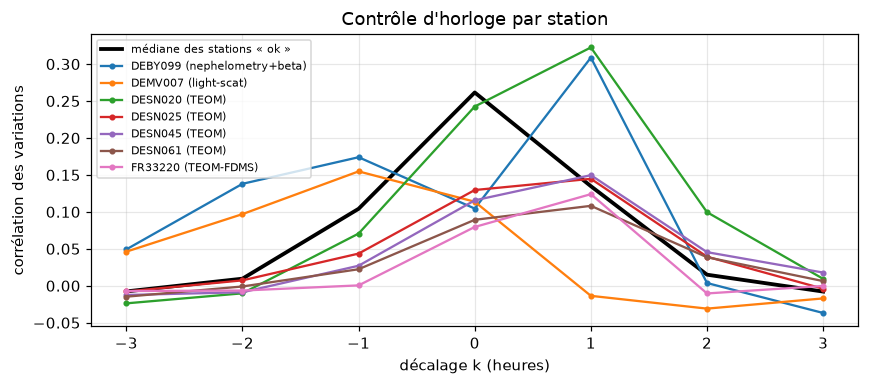

In [15]:
station_flags = pl.read_parquet(PAIRS / "clock_check_station.parquet")
station_corr = pl.read_parquet(PAIRS / "clock_station_correlations.parquet")
method = (
    pl.read_parquet(settings.paths.meta / "eea_stations_pm25.parquet")
    .select("station_code", "measurement_method")
    .unique("station_code")
)
bad = station_flags.filter(pl.col("clock_flag").is_in(["clock_mismatch", "instrument_lag"])).join(
    method, on="station_code", how="left"
)
print(
    bad.select(
        "station_code", "clock_flag", "measurement_method", "n_hours", "r_lag0", "best_lag_h", "r_best", "z"
    )
)
fig, ax = plt.subplots(figsize=(8, 3.6))
good = station_corr.join(
    station_flags.filter(pl.col("clock_flag") == "ok").select("station_code"), on="station_code"
)
typical = good.group_by("lag_h").agg(pl.col("pearson_r").median()).sort("lag_h")
ax.plot(typical["lag_h"], typical["pearson_r"], color="k", lw=2.5, label="médiane des stations « ok »")
flagged = station_corr.join(bad.select("station_code", "measurement_method"), on="station_code").sort("lag_h")
for (code_,), part in flagged.group_by("station_code", maintain_order=True):
    ax.plot(part["lag_h"], part["pearson_r"], marker=".", label=f"{code_} ({part['measurement_method'][0]})")
ax.set_xlabel("décalage k (heures)")
ax.set_ylabel("corrélation des variations")
ax.set_title("Contrôle d'horloge par station")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_horloge_stations.png")

Et le verdict paire par paire :

In [16]:
pair_flags = pl.read_parquet(PAIRS / "clock_check.parquet")
pair_flags.group_by("clock_flag").agg(
    paires=pl.len(), heures=pl.col("n_hours").sum(), r_lag0_médian=pl.col("r_lag0").median().round(3)
).sort("clock_flag")

clock_flag,paires,heures,r_lag0_médian
str,u32,u32,f64
"""clock_mismatch""",12,91128,0.201
"""clock_unverifiable""",299,2261581,0.044
"""instrument_lag""",17,187772,0.22
"""ok""",1113,11040966,0.381


> **Vérification : la contre-épreuve.** **Sans** la correction `Start − 1 h`, le test rejette **1 085 paires vérifiables
> sur 1 142 et 207 stations sur 216**. **Avec** la correction, il n'en signale plus que **29 paires et 7 stations**. Le
> test sait donc bien repérer un décalage, et notre règle est la bonne.

La paire 32200 montre pourquoi on a travaillé sur les variations : ses niveaux donnent 0,888 à $k = 0$ et 0,884 à
$k = +1$, quasiment pareil, alors que ses variations culminent nettement à $k = 0$ (0,231 contre 0,181).

Surprise en regardant les 7 stations signalées : **5 d'entre elles mesurent avec une microbalance TEOM**. Toutes ont leur
pic à $k = +1$, mais avec une corrélation **étalée** entre 0 et +1, au lieu de chuter à 0 comme pour un vrai décalage, et
ce en hiver comme en été. Ces stations ne sont pas mal réglées : le TEOM répond simplement avec environ une demi-heure de
retard.

On les a donc **gardées** (avec le statut `instrument_lag`), et la méthode de mesure devient une variable du modèle. On
exclut en revanche deux stations dont le décalage reste inexpliqué, DEBY099 (+1 h, z = 13) et DEMV007 (−1 h, z = 3,7),
soit 24 283 heures, ainsi que 10 paires en décalage individuel (70 038 heures). Enfin, **299 paires** sont
« invérifiables » : leurs variations ne suivent pas la station (corrélation médiane 0,04). On les garde avec leur drapeau,
et on les étudie au notebook 04.

## 7. L'entonnoir complet

Combien d'heures reste-t-il à la fin, et pourquoi les autres sont-elles parties ? Chaque heure de chaque segment reçoit un
statut, dans l'ordre : heure du capteur, station, horloge, humidité officielle. À chaque étape, on compte les heures, les
capteurs, les paires et les stations perdus.

In [17]:
pair_hours = pl.read_parquet(PAIRS / "pair_hours.parquet")
report._explain(report.pair_funnel(pair_hours), report.HOUR_REASONS)

step,raison,removed,remaining,capteurs_lost,capteurs_remaining,paires_lost,paires_remaining,stations_lost,stations_remaining
str,str,i64,i64,i64,i64,i64,i64,i64,i64
"""start""","""point de départ""",0,15668400,0,1399,0,1479,0,298
"""no_valid_reading""","""aucune mesure valide dans l'heure (raison dominante dans `main_flag`)""",230389,15438011,3,1396,4,1475,0,298
"""incomplete_hour""","""complétude < 75 % de la cadence propre du capteur""",800252,14637759,2,1394,8,1467,1,297
"""no_reference_station""","""segment de position sans station utilisable à ≤ 3 km""",42902,14594857,0,1394,19,1448,0,297
"""reference_not_downloaded""","""station de référence non téléchargée""",0,14594857,0,1394,0,1448,0,297
"""reference_missing""","""pas de valeur EEA PM2.5 à cette heure""",264171,14330686,0,1394,0,1448,0,297
"""reference_invalid""","""valeur EEA PM2.5 invalide (drapeau ou −999)""",410665,13920021,0,1394,5,1443,0,297
"""reference_not_verified""","""valeur EEA PM2.5 non vérifiée""",0,13920021,0,1394,0,1443,0,297
"""reference_negative_beyond_uncertainty""","""valeur EEA PM2.5 < −5 µg/m³""",3,13920018,0,1394,0,1443,0,297


Puis les heures utilisables par pays et par bande, par type de station et par méthode de mesure :

In [18]:
print(report.usable_by(pair_hours, ["country", "distance_band"]))
print(report.usable_by(pair_hours, ["country", "station_type"]))
report.usable_by(pair_hours, ["country", "method_class"])

shape: (4, 8)
┌─────────┬───────────────┬───────────────┬────────┬──────────┬──────────┬────────────────────────────┬───────────────────┐
│ country ┆ distance_band ┆ heures_paires ┆ paires ┆ capteurs ┆ stations ┆ pct_humidité_locale_fiable ┆ pct_secours_météo │
│ ---     ┆ ---           ┆ ---           ┆ ---    ┆ ---      ┆ ---      ┆ ---                        ┆ ---               │
│ str     ┆ str           ┆ u32           ┆ u32    ┆ u32      ┆ u32      ┆ f64                        ┆ f64               │
╞═════════╪═══════════════╪═══════════════╪════════╪══════════╪══════════╪════════════════════════════╪═══════════════════╡
│ DE      ┆ far           ┆ 7162545       ┆ 709    ┆ 689      ┆ 187      ┆ 26.3                       ┆ 4.51              │
│ DE      ┆ near          ┆ 5558171       ┆ 577    ┆ 555      ┆ 177      ┆ 26.9                       ┆ 4.94              │
│ FR      ┆ far           ┆ 694585        ┆ 96     ┆ 92       ┆ 40       ┆ 33.5                       ┆ 0.03          

shape: (6, 8)
┌─────────┬──────────────┬───────────────┬────────┬──────────┬──────────┬────────────────────────────┬───────────────────┐
│ country ┆ station_type ┆ heures_paires ┆ paires ┆ capteurs ┆ stations ┆ pct_humidité_locale_fiable ┆ pct_secours_météo │
│ ---     ┆ ---          ┆ ---           ┆ ---    ┆ ---      ┆ ---      ┆ ---                        ┆ ---               │
│ str     ┆ str          ┆ u32           ┆ u32    ┆ u32      ┆ u32      ┆ f64                        ┆ f64               │
╞═════════╪══════════════╪═══════════════╪════════╪══════════╪══════════╪════════════════════════════╪═══════════════════╡
│ DE      ┆ background   ┆ 5480574       ┆ 549    ┆ 538      ┆ 130      ┆ 29.6                       ┆ 2.67              │
│ DE      ┆ industrial   ┆ 303186        ┆ 33     ┆ 33       ┆ 13       ┆ 24.8                       ┆ 6.75              │
│ DE      ┆ traffic      ┆ 6936956       ┆ 704    ┆ 678      ┆ 94       ┆ 24.3                       ┆ 6.21              │
│ 

country,method_class,heures_paires,paires,capteurs,stations,pct_humidité_locale_fiable,pct_secours_météo
str,str,u32,u32,u32,u32,f64,f64
"""DE""","""beta""",623319,55,55,10,19.0,0.49
"""DE""","""nephelometry_beta""",1969271,188,181,34,23.9,0.46
"""DE""","""optical""",9375432,968,932,183,26.9,6.24
"""DE""","""teom""",752694,75,75,10,36.2,0.03
"""FR""","""beta""",216811,40,38,17,41.2,0.0
"""FR""","""optical""",494799,59,57,21,31.4,0.04
"""FR""","""teom""",362684,43,42,17,40.5,0.01
"""FR""","""unknown""",27342,3,3,3,99.3,0.0


### 7.1 Le découpage par station

Dernier point : combien de stations ont des capteurs dans les deux bandes de distance ? La colonne `cv_group` (le code de
la station) servira de groupe pour la validation croisée. On compte les stations par bande, et on trace les heures
utilisables de chaque paire en fonction de sa distance.

> **Vérification : le découpage par station.** Une station ne doit jamais se retrouver à la fois dans l'apprentissage et
> dans un test, quelle que soit la distance. Sinon, le modèle aurait déjà vu la pollution locale de la station qu'il
> prétend prédire (fuite d'information).

shape: (3, 2)
┌──────────┬──────────┐
│ bandes   ┆ stations │
│ ---      ┆ ---      │
│ str      ┆ u32      │
╞══════════╪══════════╡
│ near     ┆ 68       │
│ far      ┆ 83       │
│ far+near ┆ 144      │
└──────────┴──────────┘


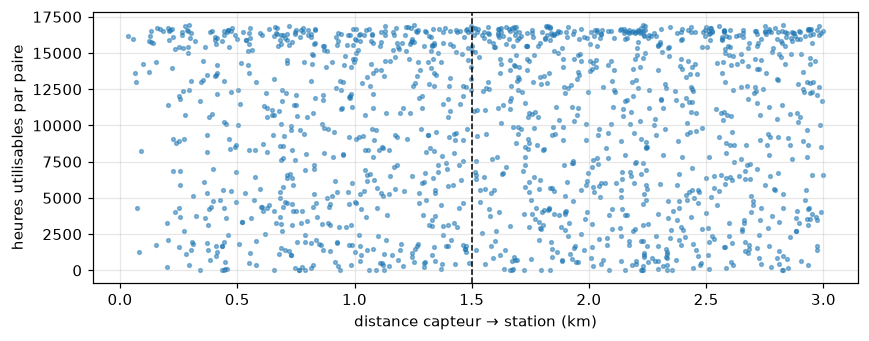

In [19]:
usable = pair_hours.filter(pl.col("status") == "ok")
bands = usable.group_by("cv_group").agg(bandes=pl.col("distance_band").unique().sort())
print(bands.with_columns(pl.col("bandes").list.join("+")).group_by("bandes").agg(stations=pl.len()))
fig, ax = plt.subplots(figsize=(8, 3.2))
per_pair = usable.group_by("pair_id").agg(heures=pl.len(), distance_km=pl.col("distance_km").first())
ax.scatter(per_pair["distance_km"], per_pair["heures"], s=6, alpha=0.5)
ax.axvline(settings.pairing.radius_train_km, color="k", ls="--", lw=1)
ax.set_xlabel("distance capteur → station (km)")
ax.set_ylabel("heures utilisables par paire")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_heures_par_paire.png")

Sur les 15,67 millions d'heures-capteur de départ, il reste **13,82 millions d'heures-paires utilisables (88,2 %)**, sur
**1 431 paires**, **1 382 capteurs** et **295 stations**. Les pertes, dans l'ordre : les heures du capteur (1,03 million,
pannes ou incomplétude), les segments sans station (0,04 million), la référence absente ou invalide (0,67 million),
l'horloge (0,09 million) et l'humidité officielle manquante (3 345 heures seulement, grâce à la station de secours). Par
pays et par bande : **Allemagne near 5,56 millions** d'heures (577 paires, 177 stations), Allemagne far 7,16 millions
(709 paires), France near 0,41 million (49 paires), France far 0,69 million (96 paires). **144 stations** ont des capteurs
dans les deux bandes.

Chaque heure perdue a sa raison dans l'entonnoir. Les 144 stations présentes dans les deux bandes devront rester entières
dans un même pli (`cv_group`).

## Ce qu'il faut retenir

- **Aucune ligne supprimée** : seulement 2,0 % des mesures de particules sont écartées, toutes par des règles physiques ou
  de cohérence. Il reste **13,82 millions d'heures-paires** utilisables (88,2 %).
- La règle « capteur figé » ne vise plus l'air propre : 12 163 plateaux d'air calme sont gardés.
- La complétude dépend de la cadence de chaque capteur (146 s en médiane, de 60 à 300 s), avec un seuil à 75 %.
- L'horloge est vérifiée sur toutes les paires : avec la correction, 7 stations sur 216 sont signalées ; sans elle, 207.
  Les 5 stations TEOM (qui répondent en retard) sont gardées.
- L'humidité officielle couvre 100 % des paires ; la sonde locale n'est fiable que 27 % du temps en Allemagne.